In [2]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm
from collections import defaultdict
import argparse
import os

from skimage.measure import block_reduce

sns.set_theme()

In [3]:
reports = []
# reports.append('report_PDEBench_2D_Rand-AutoRegressive-lr_1e-05-pde_0.0-unscaled.txt')
# reports.append('report_PDEBench_2D_Rand-AutoRegressive-lr_1e-05-pde_0.0-scaled.txt')
# reports.append('report_PDEBench_2D_Rand-AutoRegressive-lr_1e-05-pde_0.0-scaled_ke.txt')
# reports.append('report_PDEBench_2D_Rand-OneStep-lr_1e-05-pde_0.0-unscaled.txt')
# reports.append('report_PDEBench_2D_Rand-OneStep-lr_1e-05-pde_0.0-scaled.txt')
# reports.append('report_PDEBench_2D_Rand-OneStep-lr_1e-05-pde_0.0-scaled_ke.txt')
# reports.append('report_PDEBench_2D_Rand-FNO-AutoRegressive-unscaled.txt')
# reports.append('report_PDEBench_2D_Rand-FNO-AutoRegressive-scaled_mass.txt')
# reports.append('report_PDEBench_2D_Rand-FNO-AutoRegressive-scaled_momentum.txt')
# reports.append('report_PDEBench_2D_Rand-FNO_grad-AutoRegressive-unscaled.txt')
# reports.append('report_PDEBench_2D_Rand-FNO_grad-AutoRegressive-scaled_mass.txt')
# reports.append('report_PDEBench_2D_Rand-FNO_grad-AutoRegressive-scaled_momentum.txt')
# reports.append('report_PDEBench_2D_Rand-FNO-OneStep-unscaled.txt')
# reports.append('report_PDEBench_2D_Rand-FNO-OneStep-scaled_mass.txt')
# reports.append('report_PDEBench_2D_Rand-FNO-OneStep-scaled_momentum.txt')
# reports.append('report_PDEBench_2D_Rand-FNO_grad-OneStep-unscaled.txt')
# reports.append('report_PDEBench_2D_Rand-FNO_grad-OneStep-scaled_mass.txt')
# reports.append('report_PDEBench_2D_Rand-FNO_grad-OneStep-scaled_momentum.txt')
# reports.append('report_PDEBench_2D_Rand-FNO-AutoRegressive-k1-pde0.0-scaled_mass.txt')
reports.append('report_PDEBench_2D_Rand-FNO-AutoRegressive-k1-pde0.0-unscaled.txt')
# reports.append('report_PINO_2D_Vort-FNO-AutoRegressive-k1-pde0.0-unscaled.txt')
# reports.append('report_PINO_2D_Vort-FNO-Static-k1-pde0.0-unscaled.txt')

files = ['out/reports/' + report for report in reports]

datas = []
for file in files:
    data = defaultdict(list)
    current_epoch, current_values = 0, defaultdict(list)
    with open(file) as fp:
        for line in fp:
            # break line up
            (_, epoch), *terms = [s.split(': ') for s in line.split(',')]
            if int(epoch) > current_epoch:
                if current_values:
                    for label, values in current_values.items():
                        data[label].extend(block_reduce(np.array(values), (len(values) // 10,), np.mean))
                current_epoch=int(epoch)
                current_values=defaultdict(list)

            for label, value in terms:
                current_values[label].append(float(value))
    
    if current_values:
        print(current_values)
        for label, values in current_values.items():
            data[label].extend(block_reduce(np.array(values), (len(values) // 10,), np.mean))

    datas.append(data)


defaultdict(<class 'list'>, {'loss_train': [0.172, 0.0033, 0.0426, 0.0284, 0.1217, 0.1343, 0.0643, 0.0111, 0.2027, 0.048, 0.063, 0.0262, 0.0575, 0.0209, 0.0497, 0.1202, 0.0254, 0.1596, 0.0397, 0.0564, 0.0816, 0.104, 0.0591, 0.0221, 0.0274, 0.0317, 0.3423, 0.027, 0.1784, 0.0876, 0.1927, 0.0753, 0.108, 0.0021, 0.0141, 0.0451, 0.0087, 0.0169, 0.124, 0.0666, 0.2046, 0.0021, 0.0305, 0.1195, 0.0761, 0.0204, 0.0078, 0.1877, 0.0318, 0.0526, 0.0485, 0.1789, 0.1506, 0.2162, 0.0127, 0.0694, 0.0887, 0.1708, 0.0429, 0.0285, 0.0169, 0.097, 0.0912, 0.1966, 0.3235, 0.0827, 0.2352, 0.0186, 0.1129, 0.184, 0.0975, 0.1644, 0.0261, 0.0331, 0.0113, 0.0751, 0.0177, 0.0582, 0.0799, 0.145, 0.1144, 0.1652, 0.0523, 0.197, 0.0602, 0.0126, 0.1814, 0.0346, 0.0633, 0.099, 0.0901, 0.1476, 0.0241, 0.0226, 0.0813, 0.1534, 0.1774, 0.1355, 0.1375, 0.0451, 0.0479, 0.0525, 0.0449, 0.0317, 0.1179, 0.0274, 0.1613, 0.0566, 0.0498, 0.1287, 0.0515, 0.0076, 0.0506, 0.0299, 0.1243, 0.0278, 0.3703, 0.0053, 0.1156, 0.0106, 0.1194, 

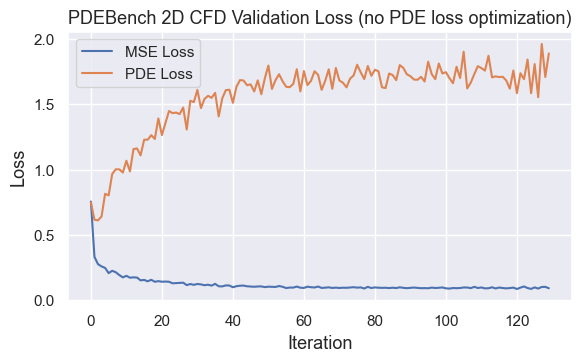

In [14]:
# plot losses
fig = plt.figure(figsize=(6.5, 3.5))

for file, data in zip(files, datas):
    for label, values in data.items():
        if 'loss' in label and 'val' in label and 'onestep' not in label:
            plt.plot(values[:-1], label=label)

    plt.title(file[len('out/reports/report_'):-4])
    plt.title('PDEBench 2D CFD Validation Loss (no PDE loss optimization)', fontsize=13)
    plt.legend(['MSE Loss', 'PDE Loss'])
    plt.xlabel('Iteration', fontsize=13)
    plt.ylabel('Loss', fontsize=13)
    plt.show()